In [1]:
import sys
import cv2
import torch
import ultralytics

print("Python:", sys.version)
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

Python: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
OpenCV: 5.0.0
PyTorch: 2.14.1+cpu
Ultralytics: 8.4.175


In [4]:
import cv2
import os

video_path = os.path.join("videos", "ua_detrac.mp4")

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Could not open video. Check the file path.")
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    duration = total_frames / fps if fps > 0 else 0

    print("Video opened successfully!")
    print("FPS:", round(fps, 2))
    print("Total frames:", total_frames)
    print("Duration:", round(duration, 2), "seconds")

cap.release()

Video opened successfully!
FPS: 30.0
Total frames: 252
Duration: 8.4 seconds


Frame loaded successfully!
Frame dimensions: (540, 960, 3)


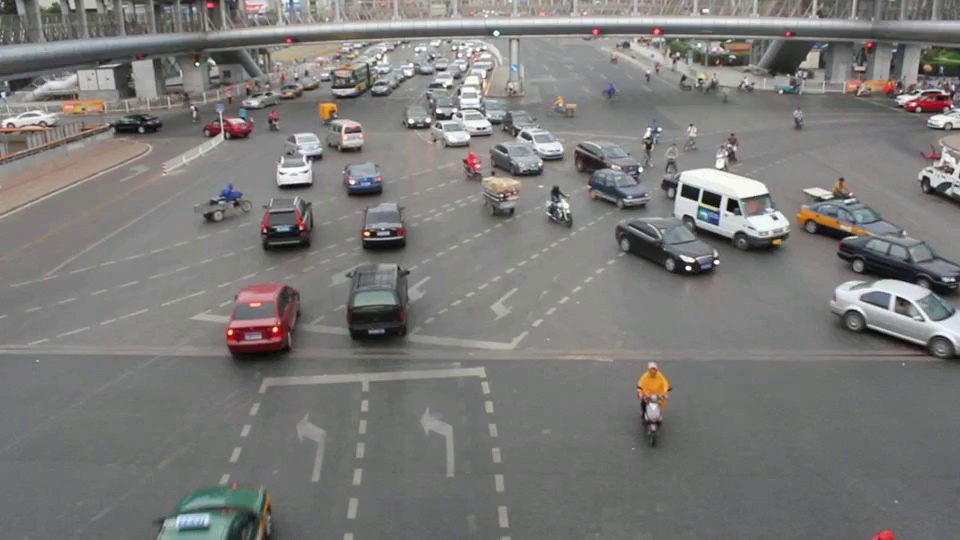

In [5]:
import cv2
from IPython.display import display, Image

cap = cv2.VideoCapture(video_path)

try:
    success, frame = cap.read()

    if success:
        print("Frame loaded successfully!")
        print("Frame dimensions:", frame.shape)

        # Resize for easier viewing
        frame = cv2.resize(frame, (960, 540))

        # Display the frame without Matplotlib
        success, encoded = cv2.imencode(".jpg", frame)

        if success:
            display(Image(data=encoded.tobytes()))
    else:
        print("Could not read the first frame.")

finally:
    cap.release()

Detection completed!

Detected objects:
car: 18
person: 1
truck: 1


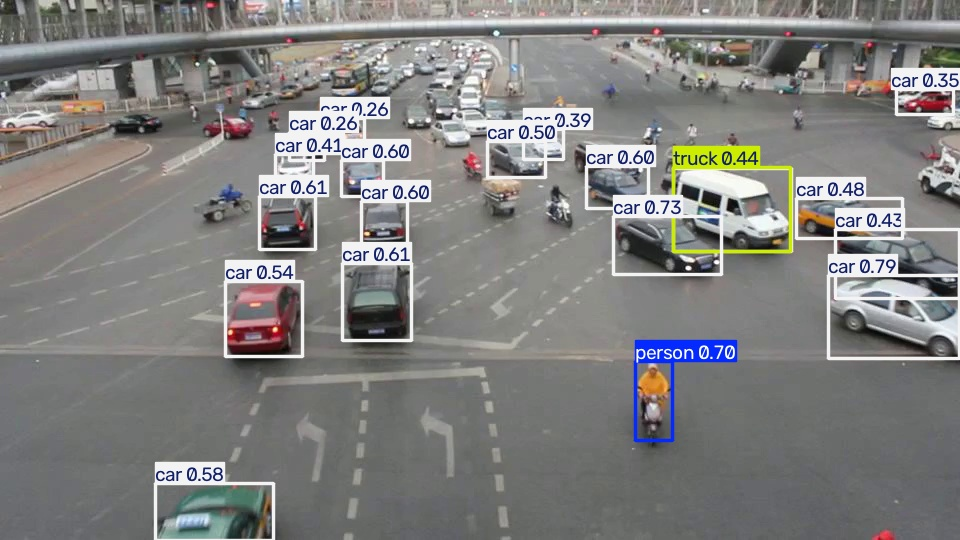

In [6]:
from ultralytics import YOLO
import cv2
from IPython.display import display, Image

# Load the pretrained YOLO model
model = YOLO("yolo26n.pt")

# Open the traffic video
cap = cv2.VideoCapture(video_path)

try:
    success, frame = cap.read()

    if success:
        # Run object detection
        results = model.predict(
            source=frame,
            conf=0.25,
            device="cpu",
            verbose=False
        )

        # Get the first frame's detection results
        result = results[0]

        # Draw bounding boxes around detected objects
        annotated_frame = result.plot()

        # Count detections by class
        detected_objects = {}

        for box in result.boxes:
            class_id = int(box.cls[0])
            class_name = model.names[class_id]

            detected_objects[class_name] = (
                detected_objects.get(class_name, 0) + 1
            )

        print("Detection completed!")
        print("\nDetected objects:")

        for class_name, count in sorted(detected_objects.items()):
            print(f"{class_name}: {count}")

        # Display the annotated frame
        encoded_success, encoded_image = cv2.imencode(
            ".jpg", annotated_frame
        )

        if encoded_success:
            display(Image(data=encoded_image.tobytes()))

    else:
        print("Could not read the video.")

finally:
    cap.release()

In [7]:
import cv2
from collections import Counter

# Read the first frame
cap = cv2.VideoCapture(video_path)

try:
    success, frame = cap.read()
finally:
    cap.release()

if not success:
    raise RuntimeError("Could not read the first video frame.")

# Vehicle classes in the COCO dataset
vehicle_classes = ["car", "motorcycle", "bus", "truck"]

# Test different confidence thresholds
confidence_levels = [0.25, 0.15, 0.10]

for confidence in confidence_levels:

    results = model.predict(
        source=frame,
        conf=confidence,
        imgsz=960,
        device="cpu",
        verbose=False
    )

    result = results[0]

    detected_vehicles = Counter()

    for box in result.boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]

        if class_name in vehicle_classes:
            detected_vehicles[class_name] += 1

    print(f"\nConfidence threshold: {confidence}")
    print("Cars:", detected_vehicles["car"])
    print("Motorcycles:", detected_vehicles["motorcycle"])
    print("Buses:", detected_vehicles["bus"])
    print("Trucks:", detected_vehicles["truck"])
    print("Total vehicles:", sum(detected_vehicles.values()))


Confidence threshold: 0.25
Cars: 22
Motorcycles: 2
Buses: 1
Trucks: 1
Total vehicles: 26

Confidence threshold: 0.15
Cars: 25
Motorcycles: 3
Buses: 1
Trucks: 1
Total vehicles: 30

Confidence threshold: 0.1
Cars: 30
Motorcycles: 7
Buses: 1
Trucks: 2
Total vehicles: 40


Detection results at confidence = 0.25


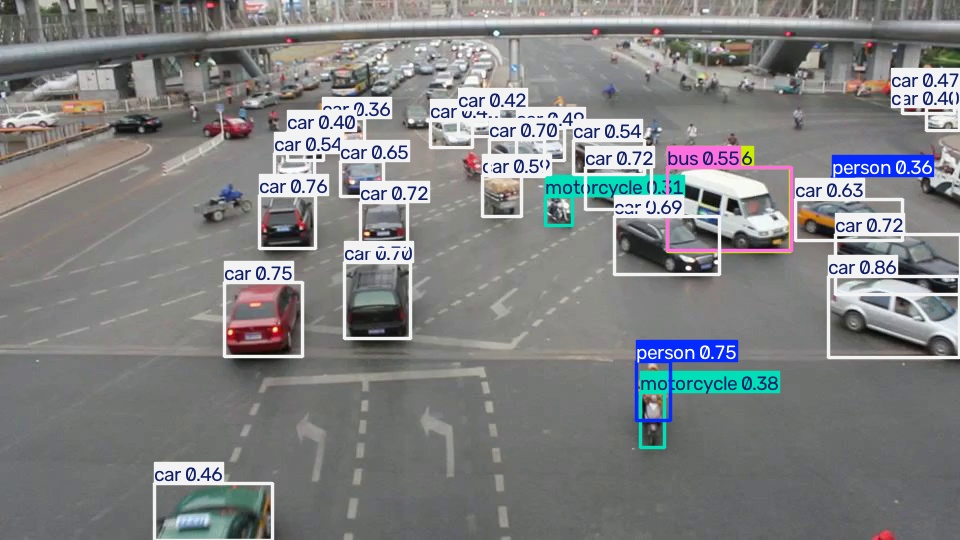

Detection results at confidence = 0.15


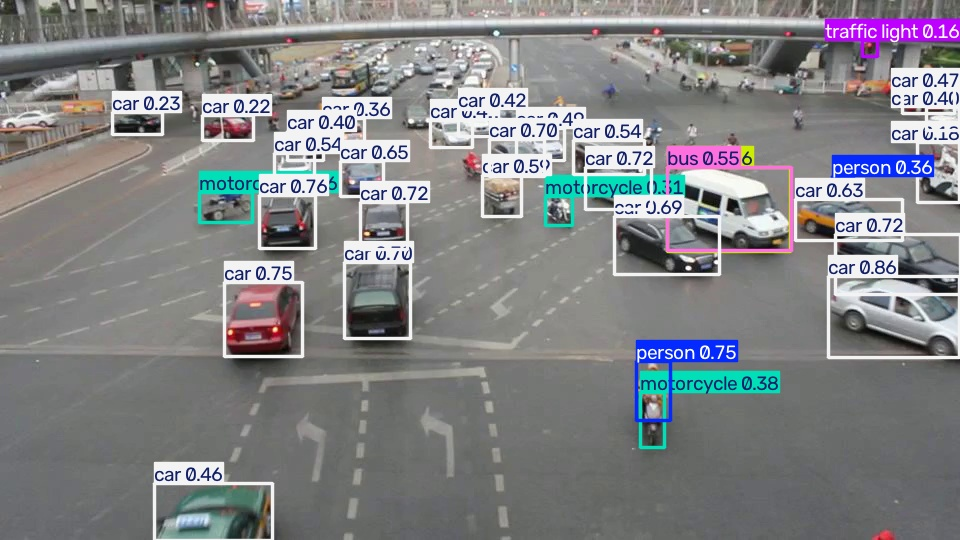

Detection results at confidence = 0.1


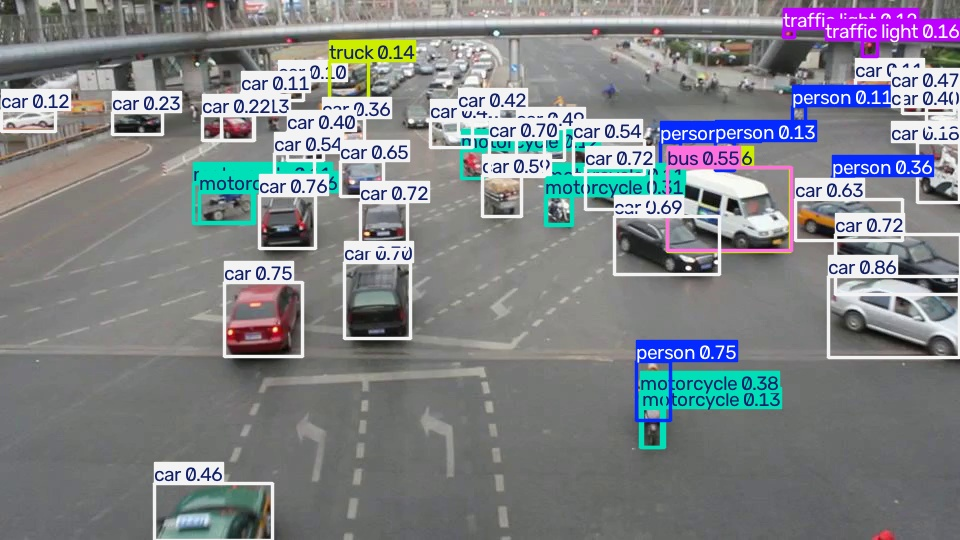

In [8]:
import cv2
from IPython.display import display, Image

# Read the first frame
cap = cv2.VideoCapture(video_path)

try:
    success, frame = cap.read()
finally:
    cap.release()

if not success:
    raise RuntimeError("Could not read the video frame.")

confidence_levels = [0.25, 0.15, 0.10]

for confidence in confidence_levels:

    result = model.predict(
        source=frame,
        conf=confidence,
        imgsz=960,
        device="cpu",
        verbose=False
    )[0]

    # Draw the bounding boxes and labels
    annotated_frame = result.plot()

    print(f"Detection results at confidence = {confidence}")

    # Resize for easier viewing
    annotated_frame = cv2.resize(
        annotated_frame, (960, 540)
    )

    success, encoded = cv2.imencode(
        ".jpg", annotated_frame
    )

    if success:
        display(Image(data=encoded.tobytes()))

In [9]:
# VehicleAI detection configuration

CONFIDENCE_THRESHOLD = 0.15
IMAGE_SIZE = 960
DEVICE = "cpu"

VEHICLE_CLASSES = ["car", "motorcycle", "bus", "truck"]

print("VehicleAI configuration")
print("------------------------")
print("Model:", "yolo26n.pt")
print("Confidence threshold:", CONFIDENCE_THRESHOLD)
print("Image size:", IMAGE_SIZE)
print("Device:", DEVICE)
print("Vehicle classes:", VEHICLE_CLASSES)

VehicleAI configuration
------------------------
Model: yolo26n.pt
Confidence threshold: 0.15
Image size: 960
Device: cpu
Vehicle classes: ['car', 'motorcycle', 'bus', 'truck']


In [10]:
import cv2
import gc
from collections import defaultdict

# Store each unique track ID and its vehicle class
tracked_vehicles = {}

# Open the traffic video
cap = cv2.VideoCapture(video_path)

frames_to_process = 30
frames_processed = 0

try:
    while frames_processed < frames_to_process:

        success, frame = cap.read()

        if not success:
            break

        # Detect and track objects
        result = model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=CONFIDENCE_THRESHOLD,
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            verbose=False
        )[0]

        frames_processed += 1

        # Process detections with tracking IDs
        if result.boxes.id is not None:

            for box in result.boxes:

                class_id = int(box.cls[0])
                class_name = model.names[class_id]

                # Keep only vehicles
                if class_name not in VEHICLE_CLASSES:
                    continue

                track_id = int(box.id[0])

                # Record each ID the first time we see it
                if track_id not in tracked_vehicles:
                    tracked_vehicles[track_id] = class_name

        if frames_processed % 10 == 0:
            print(
                f"Processed {frames_processed} frames | "
                f"Unique track IDs: {len(tracked_vehicles)}"
            )

        del result, frame

finally:
    cap.release()
    gc.collect()

# Count track IDs by vehicle class
vehicle_counts = defaultdict(int)

for class_name in tracked_vehicles.values():
    vehicle_counts[class_name] += 1

print("\n========== TRACKING SUMMARY ==========")
print("Frames processed:", frames_processed)
print("Unique track IDs:", len(tracked_vehicles))

for vehicle in VEHICLE_CLASSES:
    print(f"{vehicle}: {vehicle_counts[vehicle]}")

print("======================================")

Processed 10 frames | Unique track IDs: 28
Processed 20 frames | Unique track IDs: 30
Processed 30 frames | Unique track IDs: 32

========== TRACKING SUMMARY ==========
Frames processed: 30
Unique track IDs: 32
car: 26
motorcycle: 3
bus: 2
truck: 1


Tracking visualization generated!


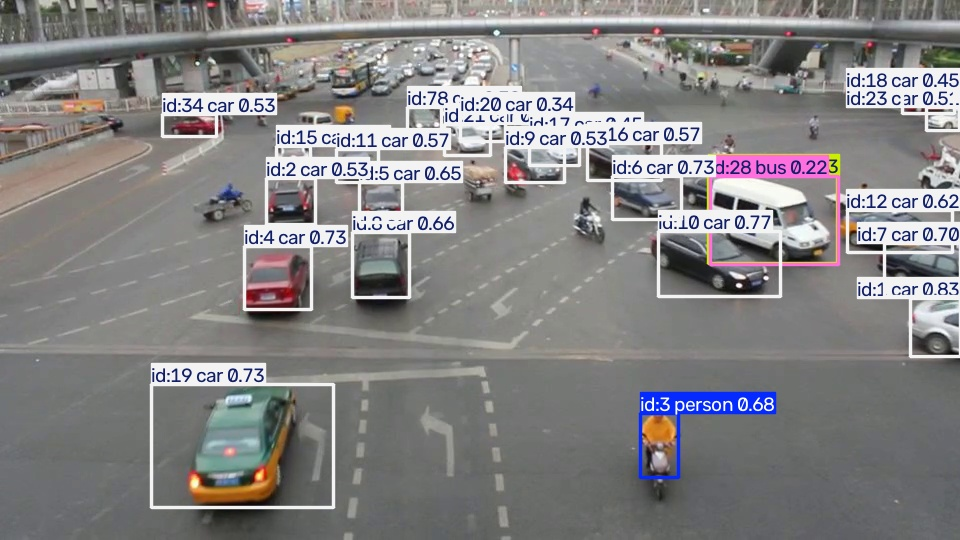

In [11]:
import cv2
from IPython.display import display, Image

# Open the video again
cap = cv2.VideoCapture(video_path)

try:
    # Move to frame 20
    cap.set(cv2.CAP_PROP_POS_FRAMES, 19)

    success, frame = cap.read()

    if success:

        # Detect and track objects in this frame
        result = model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=CONFIDENCE_THRESHOLD,
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            verbose=False
        )[0]

        # Draw boxes, labels, and IDs
        annotated_frame = result.plot()

        print("Tracking visualization generated!")

        # Resize for easier viewing
        annotated_frame = cv2.resize(
            annotated_frame, (960, 540)
        )

        success, encoded = cv2.imencode(
            ".jpg", annotated_frame
        )

        if success:
            display(Image(data=encoded.tobytes()))

    else:
        print("Could not read frame 20.")

finally:
    cap.release()

In [12]:
import cv2
import gc

cap = cv2.VideoCapture(video_path)

output_path = "tracking_preview.mp4"

fps = cap.get(cv2.CAP_PROP_FPS)
writer = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (960, 540)
)

frames_processed = 0
frames_to_process = 30

try:
    while frames_processed < frames_to_process:
        success, frame = cap.read()

        if not success:
            break

        result = model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=CONFIDENCE_THRESHOLD,
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            verbose=False
        )[0]

        # Draw boxes, classes, and tracking IDs
        annotated_frame = result.plot()

        # Resize to match the output video's dimensions
        annotated_frame = cv2.resize(
            annotated_frame,
            (960, 540)
        )

        writer.write(annotated_frame)

        frames_processed += 1

        if frames_processed % 10 == 0:
            print(f"Processed {frames_processed} frames")

        del result, frame, annotated_frame

finally:
    cap.release()
    writer.release()
    gc.collect()

print("\nTracking preview saved:", output_path)
print("Frames processed:", frames_processed)

Processed 10 frames
Processed 20 frames
Processed 30 frames

Tracking preview saved: tracking_preview.mp4
Frames processed: 30


In [13]:
from IPython.display import Video, display

display(Video("tracking_preview.mp4", embed=True))

In [14]:
import os
import cv2

output_path = "tracking_preview.mp4"

print("File exists:", os.path.exists(output_path))

if os.path.exists(output_path):
    print("File size:", round(os.path.getsize(output_path) / 1024, 2), "KB")

    cap = cv2.VideoCapture(output_path)

    print("Video opened:", cap.isOpened())
    print("Frames saved:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))

    cap.release()

File exists: True
File size: 1154.0 KB
Video opened: True
Frames saved: 30
FPS: 30.0


In [15]:
from IPython.display import display, FileLink

display(FileLink("tracking_preview.mp4"))

C:\Users\Yash\Vehicle_AI\tracking_preview.mp4

In [16]:
import cv2
import os

output_path = "tracking_preview.mp4"

print("File exists:", os.path.exists(output_path))

if os.path.exists(output_path):
    print("File size:", round(os.path.getsize(output_path) / 1024, 2), "KB")

    cap = cv2.VideoCapture(output_path)

    print("Video opened:", cap.isOpened())
    print("Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))

    success, frame = cap.read()
    print("First frame readable:", success)

    if success:
        print("Frame dimensions:", frame.shape)

    cap.release()

File exists: True
File size: 1154.0 KB
Video opened: True
Frames: 30
FPS: 30.0
First frame readable: True
Frame dimensions: (540, 960, 3)


Frame 1


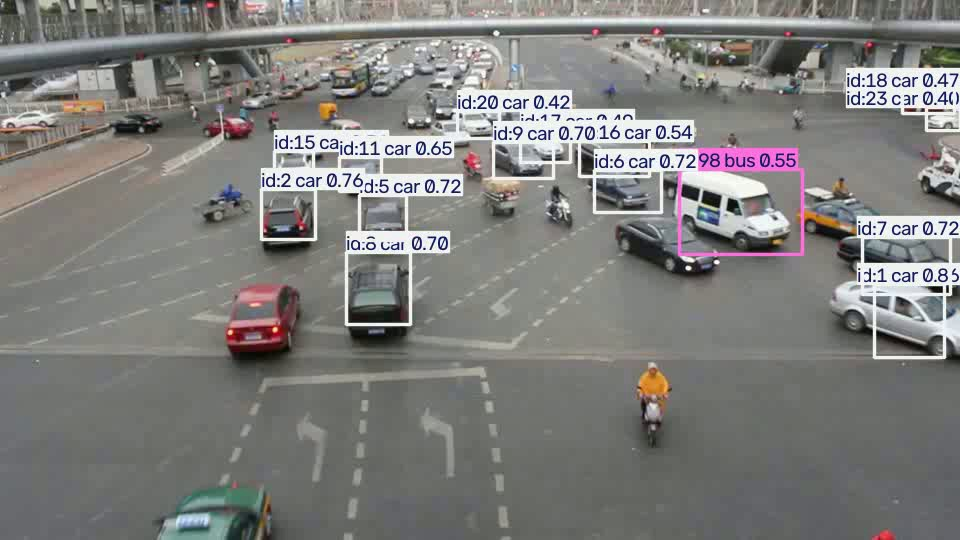

Frame 10


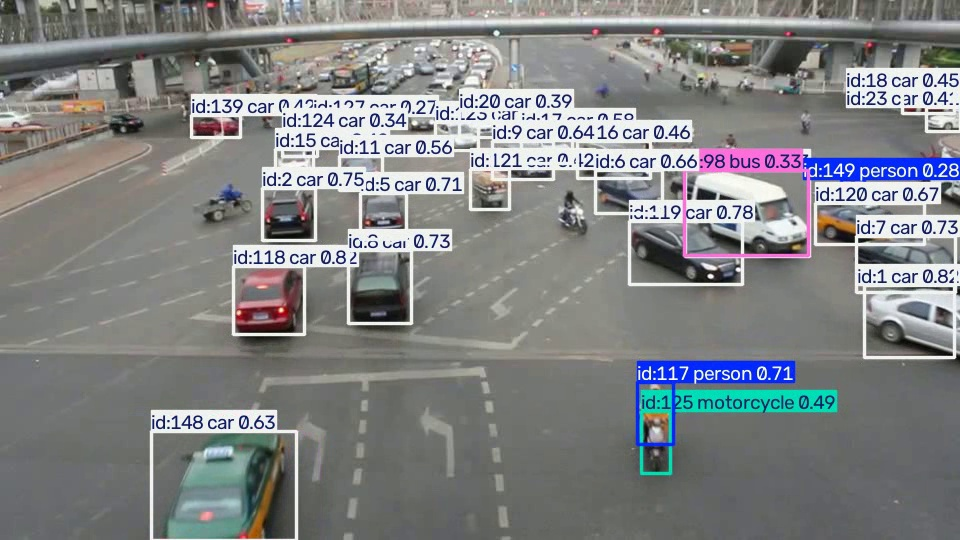

Frame 20


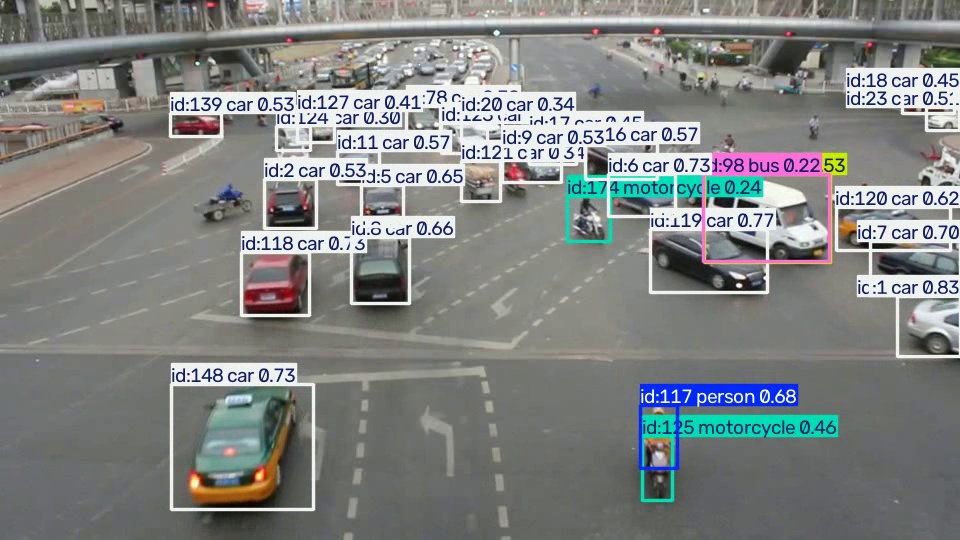

Frame 30


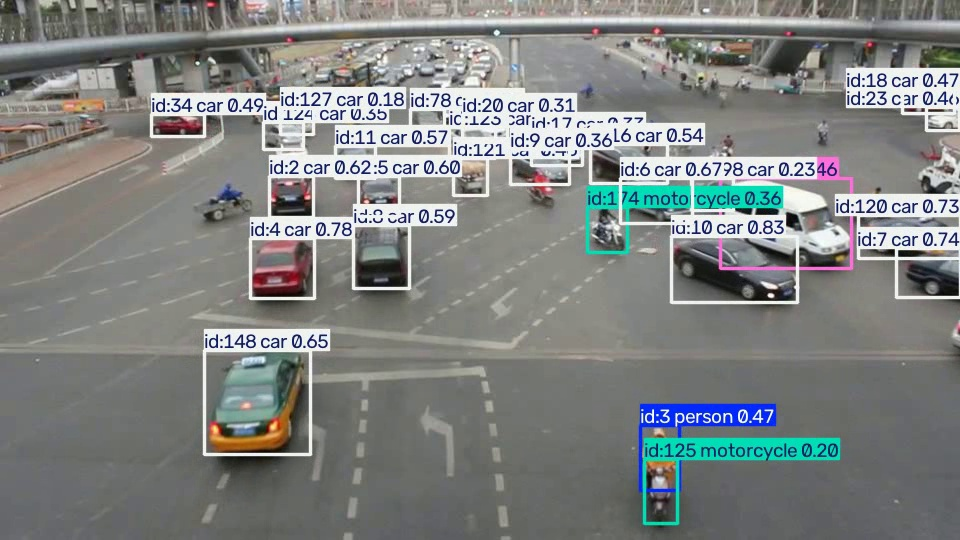

In [17]:
import cv2
from IPython.display import display, Image

cap = cv2.VideoCapture("tracking_preview.mp4")

try:
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    sample_frames = [0, 9, 19, 29]

    for frame_index in sample_frames:
        if frame_index >= total_frames:
            continue

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
        success, frame = cap.read()

        if success:
            frame = cv2.resize(frame, (960, 540))
            _, encoded = cv2.imencode(".jpg", frame)

            print(f"Frame {frame_index + 1}")
            display(Image(data=encoded.tobytes()))
finally:
    cap.release()

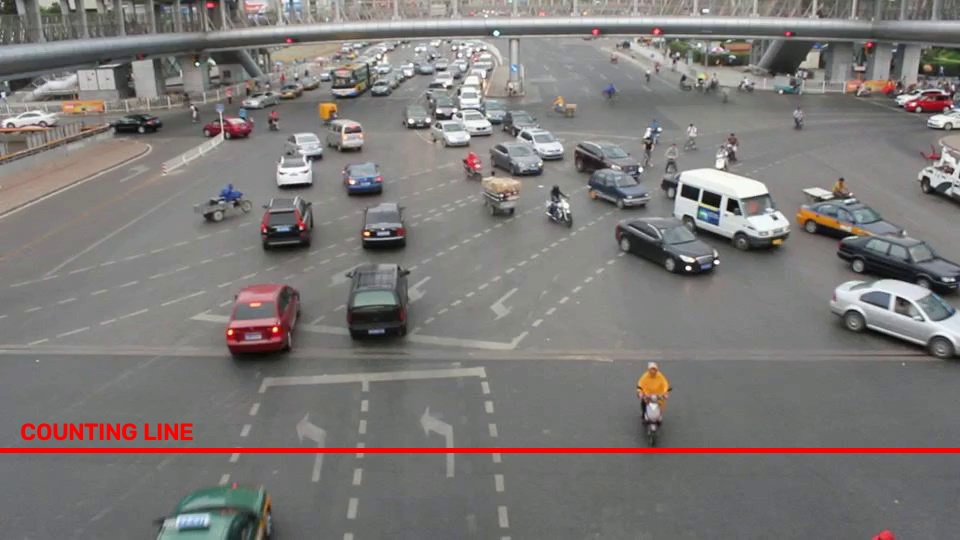

In [20]:
import cv2
from IPython.display import display, Image

LINE_Y = 450

cap = cv2.VideoCapture(video_path)

try:
    success, frame = cap.read()

    if success:
        frame = cv2.resize(frame, (960, 540))

        # Draw the virtual counting line
        cv2.line(
            frame,
            (0, LINE_Y),
            (960, LINE_Y),
            (0, 0, 255),
            3
        )

        # Add a label
        cv2.putText(
            frame,
            "COUNTING LINE",
            (20, LINE_Y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        _, encoded = cv2.imencode(".jpg", frame)
        display(Image(data=encoded.tobytes()))

    else:
        print("Could not read the video.")

finally:
    cap.release()

In [21]:
import cv2
import gc
from collections import defaultdict

# Counting configuration
LINE_Y = 450

# Reset counting data
counted_vehicle_ids = set()
vehicle_counts = defaultdict(int)
previous_positions = {}

frames_processed = 0

cap = cv2.VideoCapture(video_path)

try:
    while True:
        success, frame = cap.read()

        if not success:
            break

        # Keep dimensions consistent with our counting line
        frame = cv2.resize(frame, (960, 540))

        # Detect and track vehicles
        result = model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=CONFIDENCE_THRESHOLD,
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            verbose=False
        )[0]

        frames_processed += 1

        if result.boxes.id is not None:
            for box in result.boxes:
                class_id = int(box.cls[0])
                class_name = model.names[class_id]

                if class_name not in VEHICLE_CLASSES:
                    continue

                track_id = int(box.id[0])

                # Calculate the center of the bounding box
                x1, y1, x2, y2 = map(
                    int, box.xyxy[0].tolist()
                )
                center_y = (y1 + y2) // 2

                # Retrieve the previous vertical position
                previous_y = previous_positions.get(track_id)

                if previous_y is not None:
                    crossed_line = (
                        previous_y < LINE_Y <= center_y
                        or previous_y > LINE_Y >= center_y
                    )

                    # Count each track ID only once
                    if (
                        crossed_line
                        and track_id not in counted_vehicle_ids
                    ):
                        counted_vehicle_ids.add(track_id)
                        vehicle_counts[class_name] += 1

                        print(
                            f"Vehicle crossed | "
                            f"ID: {track_id} | "
                            f"Type: {class_name}"
                        )

                # Save position for the next frame
                previous_positions[track_id] = center_y

        if frames_processed % 30 == 0:
            print(f"Processed {frames_processed} frames")

        del result, frame

finally:
    cap.release()
    gc.collect()

print("\n========== TRAFFIC SUMMARY ==========")
print("Frames processed:", frames_processed)
print("Counting line:", LINE_Y)
print("Total crossings:", sum(vehicle_counts.values()))

for vehicle in VEHICLE_CLASSES:
    print(f"{vehicle}: {vehicle_counts[vehicle]}")

print("=====================================")

Vehicle crossed | ID: 232 | Type: motorcycle
Vehicle crossed | ID: 256 | Type: car
Processed 30 frames
Processed 60 frames
Vehicle crossed | ID: 375 | Type: car
Processed 90 frames
Vehicle crossed | ID: 424 | Type: bus
Vehicle crossed | ID: 536 | Type: bus
Vehicle crossed | ID: 580 | Type: car
Processed 120 frames
Processed 150 frames
Processed 180 frames
Vehicle crossed | ID: 681 | Type: car
Processed 210 frames
Processed 240 frames

========== TRAFFIC SUMMARY ==========
Frames processed: 252
Counting line: 450
Total crossings: 7
car: 4
motorcycle: 1
bus: 2
truck: 0


In [22]:
import cv2
import gc
from collections import defaultdict

LINE_Y = 450

counted_vehicle_ids = set()
vehicle_counts = defaultdict(int)
previous_positions = {}

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
output_path = "traffic_analytics.mp4"

writer = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (960, 540)
)

frames_processed = 0

try:
    while True:
        success, frame = cap.read()

        if not success:
            break

        frame = cv2.resize(frame, (960, 540))

        result = model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=CONFIDENCE_THRESHOLD,
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            verbose=False
        )[0]

        frames_processed += 1

        if result.boxes.id is not None:
            for box in result.boxes:
                class_id = int(box.cls[0])
                class_name = model.names[class_id]

                if class_name not in VEHICLE_CLASSES:
                    continue

                track_id = int(box.id[0])

                x1, y1, x2, y2 = map(
                    int, box.xyxy[0].tolist()
                )

                center_y = (y1 + y2) // 2
                previous_y = previous_positions.get(track_id)

                if previous_y is not None:
                    crossed_line = (
                        previous_y < LINE_Y <= center_y
                        or previous_y > LINE_Y >= center_y
                    )

                    if (
                        crossed_line
                        and track_id not in counted_vehicle_ids
                    ):
                        counted_vehicle_ids.add(track_id)
                        vehicle_counts[class_name] += 1

                previous_positions[track_id] = center_y

                # Draw the vehicle box
                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

                # Draw vehicle class and tracking ID
                cv2.putText(
                    frame,
                    f"{class_name} ID:{track_id}",
                    (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 0),
                    1
                )

        # Draw the counting line
        cv2.line(
            frame,
            (0, LINE_Y),
            (960, LINE_Y),
            (0, 0, 255),
            2
        )

        # Draw the current traffic summary
        total_count = sum(vehicle_counts.values())

        cv2.putText(
            frame,
            f"Total crossings: {total_count}",
            (15, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 255, 255),
            2
        )

        y_text = 60

        for vehicle in VEHICLE_CLASSES:
            cv2.putText(
                frame,
                f"{vehicle}: {vehicle_counts[vehicle]}",
                (15, y_text),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 255, 255),
                2
            )
            y_text += 25

        writer.write(frame)

        if frames_processed % 60 == 0:
            print(f"Processed {frames_processed} frames")

        del result, frame

finally:
    cap.release()
    writer.release()
    gc.collect()

print("\nAnnotated video saved:", output_path)
print("Frames processed:", frames_processed)
print("Total crossings:", sum(vehicle_counts.values()))
print("Vehicle counts:", dict(vehicle_counts))

Processed 60 frames
Processed 120 frames
Processed 180 frames
Processed 240 frames

Annotated video saved: traffic_analytics.mp4
Frames processed: 252
Total crossings: 7
Vehicle counts: {'car': 4, 'motorcycle': 1, 'bus': 2, 'truck': 0}


Total frames: 252
Frame 31


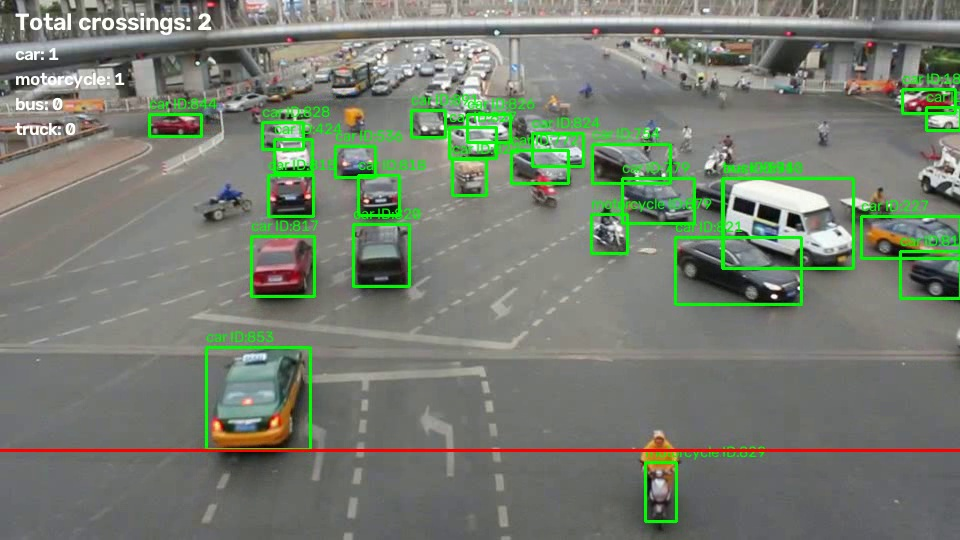

Frame 91


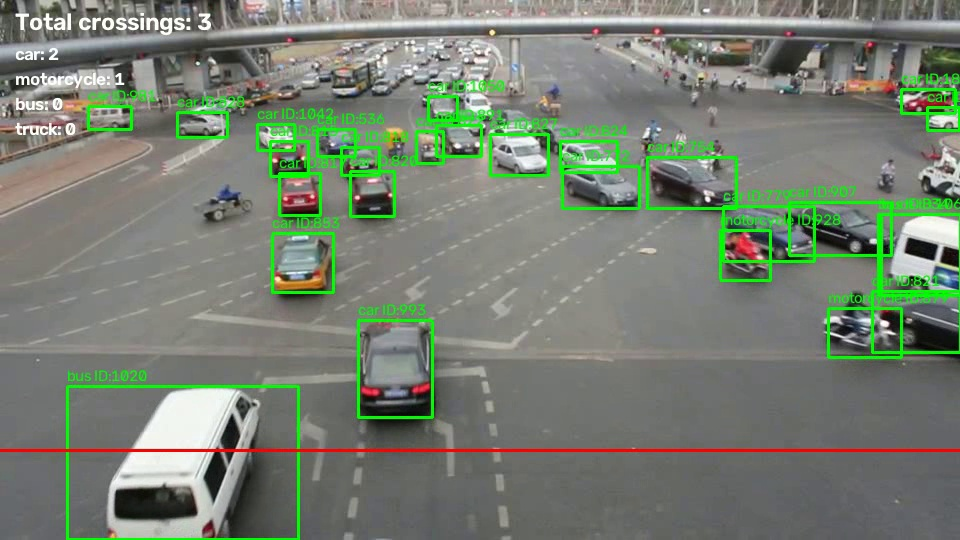

Frame 151


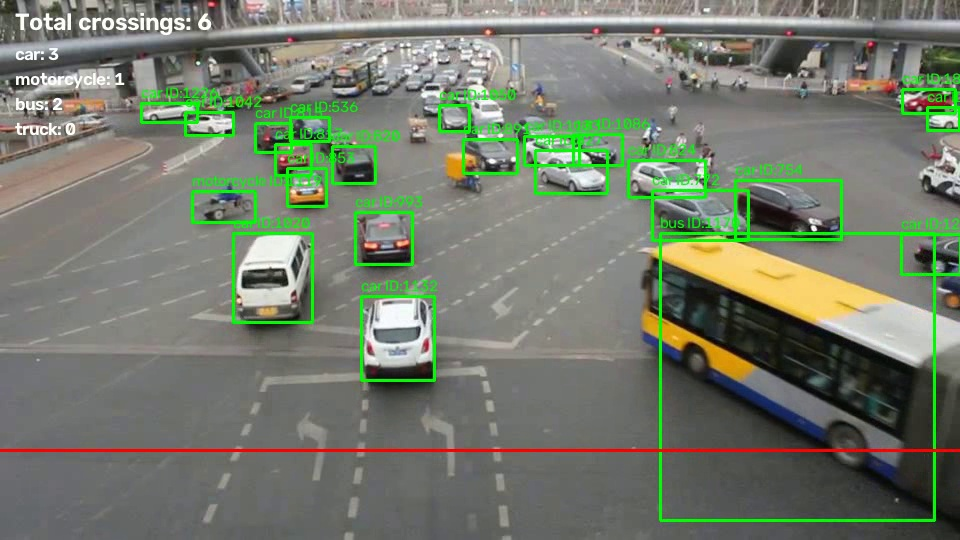

Frame 211


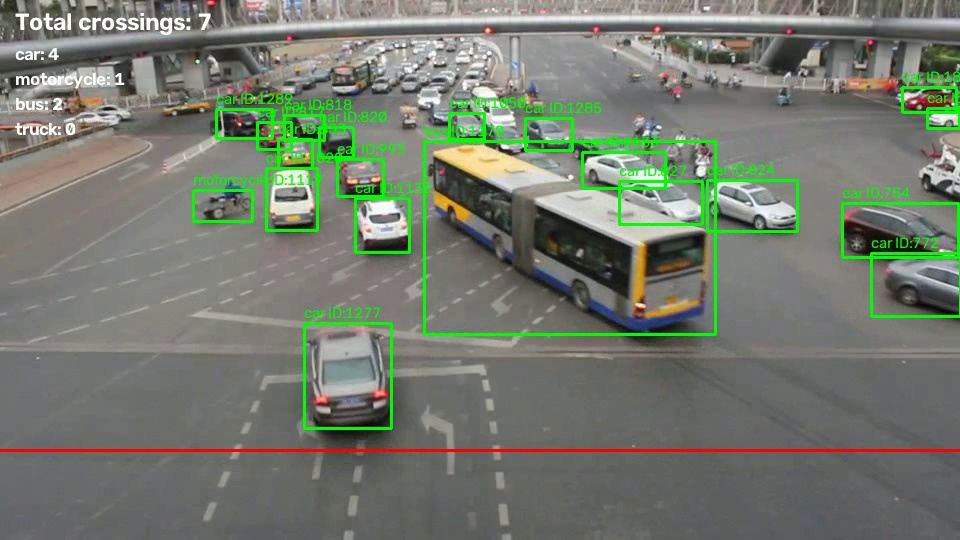

Frame 251


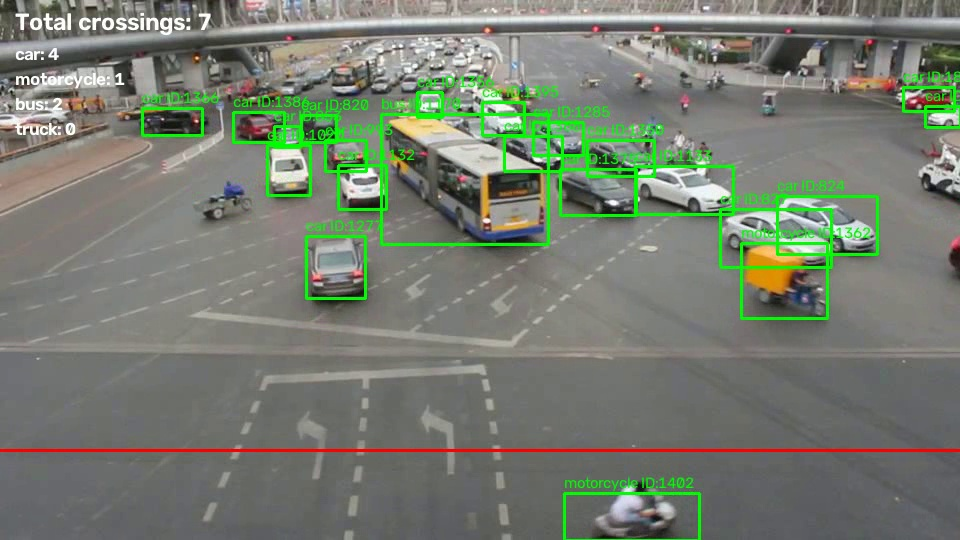

In [23]:
import cv2
from IPython.display import display, Image

output_path = "traffic_analytics.mp4"

cap = cv2.VideoCapture(output_path)

try:
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Inspect the beginning, middle, and end
    sample_frames = [30, 90, 150, 210, 250]

    print("Total frames:", total_frames)

    for frame_number in sample_frames:
        if frame_number >= total_frames:
            continue

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
        success, frame = cap.read()

        if success:
            print(f"Frame {frame_number + 1}")

            _, encoded = cv2.imencode(".jpg", frame)
            display(Image(data=encoded.tobytes()))

finally:
    cap.release()

In [27]:
%pip install pandas

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.9 MB 2.2 MB/s eta 0:00:05
   ----- ---------------------------------- 1.3/9.9 MB 2.5 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/9.9 MB 2.9 MB/s eta 0:00:03
   ----------- ---------------------------- 2.9/9.9 MB 3.2 MB/s eta 0:00:03
   ----------------- ---------------------- 4.2/9.9 MB 3.7 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.9 MB 4.2 MB/s eta 0:00:02
   ------------------------------ --------- 7.6/9.9 MB 4.9 MB/s eta 0:00:01
   ---------------------------------------- 9.9/9.9 MB 5.7 MB/s  0:00:01

   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ----

In [28]:
import pandas as pd

# Traffic counts obtained from our video
vehicle_counts = {
    "car": 4,
    "motorcycle": 1,
    "bus": 2,
    "truck": 0
}

# Total number of vehicles counted crossing the line
total_crossings = sum(vehicle_counts.values())

# Create a table
traffic_data = pd.DataFrame({
    "Vehicle Type": list(vehicle_counts.keys()),
    "Count": list(vehicle_counts.values())
})

# Calculate the percentage for each vehicle type
traffic_data["Percentage"] = (
    traffic_data["Count"] / total_crossings * 100
).round(2)

# Display the table
print("Total Crossings:", total_crossings)
display(traffic_data)

Total Crossings: 7


,Vehicle Type,Count,Percentage
0,car,4,57.14
1,motorcycle,1,14.29
2,bus,2,28.57
3,truck,0,0.00


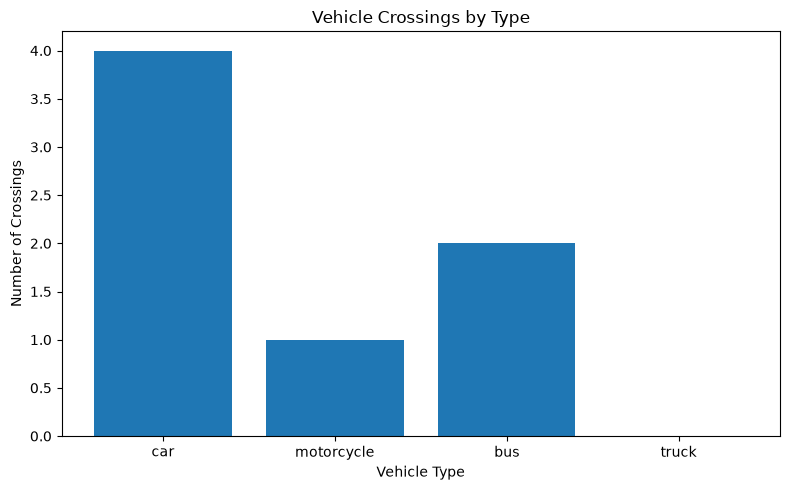

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    traffic_data["Vehicle Type"],
    traffic_data["Count"]
)

plt.title("Vehicle Crossings by Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Crossings")

plt.tight_layout()
plt.show()

In [30]:
# Store details of every detected line crossing
crossing_events = []

print("Crossing event recorder initialized.")

Crossing event recorder initialized.


In [31]:
import cv2
import pandas as pd
from IPython.display import display

# Video settings
video_path = "videos/ua_detrac.mp4"
LINE_Y = 450

# Reset tracking and counting data
previous_positions = {}
counted_vehicle_ids = set()
crossing_events = []

# Open the video
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

frame_number = 0

while cap.isOpened():
    success, frame = cap.read()

    if not success:
        break

    frame_number += 1

    # Resize the frame
    frame = cv2.resize(frame, (960, 540))

    # Detect and track vehicles
    result = model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=CONFIDENCE_THRESHOLD,
        imgsz=IMAGE_SIZE,
        device=DEVICE,
        verbose=False
    )[0]

    # Process tracked vehicles
    if result.boxes is not None and result.boxes.id is not None:

        boxes = result.boxes.xyxy.cpu().numpy()
        track_ids = result.boxes.id.int().cpu().tolist()
        class_ids = result.boxes.cls.int().cpu().tolist()

        for box, track_id, class_id in zip(
            boxes, track_ids, class_ids
        ):
            class_name = model.names[class_id]

            # Ignore non-vehicle classes
            if class_name not in VEHICLE_CLASSES:
                continue

            # Calculate the center of the vehicle
            x1, y1, x2, y2 = box
            center_y = int((y1 + y2) / 2)

            previous_y = previous_positions.get(track_id)

            # Check whether the vehicle crossed the line
            crossed_line = (
                previous_y is not None
                and (
                    previous_y < LINE_Y <= center_y
                    or previous_y > LINE_Y >= center_y
                )
            )

            # Record each tracked ID only once
            if (
                crossed_line
                and track_id not in counted_vehicle_ids
            ):
                timestamp = frame_number / fps

                crossing_events.append({
                    "Timestamp (seconds)": round(timestamp, 2),
                    "Vehicle ID": track_id,
                    "Vehicle Type": class_name
                })

                counted_vehicle_ids.add(track_id)

            previous_positions[track_id] = center_y

    if frame_number % 60 == 0:
        print(f"Processed {frame_number} frames")

cap.release()

print("\nVideo processing completed.")
print("Total frames processed:", frame_number)
print("Total recorded crossings:", len(crossing_events))

Processed 60 frames
Processed 120 frames
Processed 180 frames
Processed 240 frames

Video processing completed.
Total frames processed: 252
Total recorded crossings: 7


In [32]:
# Convert recorded crossing events into a DataFrame
events_df = pd.DataFrame(crossing_events)

# Sort events by timestamp
if not events_df.empty:
    events_df = events_df.sort_values(
        "Timestamp (seconds)"
    ).reset_index(drop=True)

# Display the results
display(events_df)

,Timestamp (seconds),Vehicle ID,Vehicle Type
0,0.43,1425,motorcycle
1,0.67,1449,car
2,2.37,1567,car
3,3.23,1616,bus
4,4.00,1728,bus
5,4.00,1772,car
6,6.43,1873,car


In [33]:
# Define the duration of each interval
INTERVAL_SECONDS = 2

# Assign each crossing to a time interval
events_df["Time Interval"] = (
    events_df["Timestamp (seconds)"] // INTERVAL_SECONDS
).astype(int) * INTERVAL_SECONDS

# Count crossings by interval and vehicle type
traffic_over_time = pd.crosstab(
    events_df["Time Interval"],
    events_df["Vehicle Type"]
)

# Include intervals with zero crossings
traffic_over_time = traffic_over_time.reindex(
    range(0, 10, 2),
    fill_value=0
)

# Calculate total crossings in each interval
traffic_over_time["Total"] = traffic_over_time.sum(axis=1)

print("Traffic crossings by 2-second interval:")
display(traffic_over_time)

Traffic crossings by 2-second interval:


Vehicle Type,bus,car,motorcycle,Total
Time Interval,,,,
0,0,1,1,2
2,1,1,0,2
4,1,1,0,2
6,0,1,0,1
8,0,0,0,0


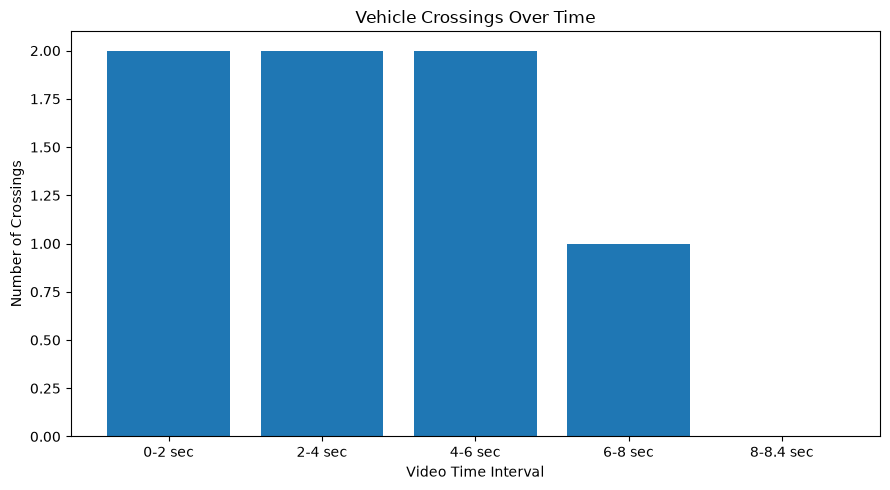

In [34]:
import matplotlib.pyplot as plt

# Create readable interval labels
interval_labels = [
    f"{start}-{min(start + 2, 8.4):g} sec"
    for start in traffic_over_time.index
]

# Extract total crossings per interval
crossings = traffic_over_time["Total"]

# Create the chart
plt.figure(figsize=(9, 5))

plt.bar(interval_labels, crossings)

plt.title("Vehicle Crossings Over Time")
plt.xlabel("Video Time Interval")
plt.ylabel("Number of Crossings")

plt.tight_layout()
plt.show()

In [35]:
# Video duration in seconds
video_duration = total_frames / fps

# Total recorded vehicle crossings
total_crossings = len(crossing_events)

# Calculate observed crossing rates
crossings_per_second = total_crossings / video_duration
crossings_per_minute = crossings_per_second * 60
crossings_per_hour = crossings_per_second * 3600

print("TRAFFIC FLOW SUMMARY")
print("-" * 35)
print(f"Video duration: {video_duration:.2f} seconds")
print(f"Recorded crossings: {total_crossings}")
print(f"Observed rate: {crossings_per_minute:.2f} crossings/minute")
print(f"Extrapolated rate: {crossings_per_hour:.2f} crossings/hour")

TRAFFIC FLOW SUMMARY
-----------------------------------
Video duration: 8.40 seconds
Recorded crossings: 7
Observed rate: 50.00 crossings/minute
Extrapolated rate: 3000.00 crossings/hour
